# RQ2 — Temperature Analysis

This notebook evaluates whether GPT-OSS performance varies across temperature settings. Projects are the paired experimental units, and all temperature configurations are evaluated on the same projects.

The automatic statistical workflow is:

1. apply Shapiro–Wilk to every temperature configuration;
2. if normality is not rejected for all configurations, use repeated-measures ANOVA and test sphericity with Mauchly's test;
3. apply the Greenhouse–Geisser correction when sphericity is rejected;
4. otherwise, use the Friedman test;
5. perform paired post-hoc comparisons only after a significant omnibus result;
6. adjust the complete pairwise family with Holm's procedure and report Hedges' $g$ or matched-pairs rank-biserial correlation ($r_{rb}$), according to the selected route.

This notebook analyzes project-level Macro-F1. Seed disagreement, runtime, and commit-level prediction stability require their corresponding data and are not inferred from Macro-F1 alone.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import pingouin as pg
from IPython.display import Markdown, display


PROJECT_COLUMN = "project"
MODEL_NAME = "GPT-OSS 20B"

# Supports running the notebook either from results/rq2/analysis/
# or from the repository root.
DATA_PATH = Path("../metrics/temperature_macro_f1.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("results/rq2/metrics/temperature_macro_f1.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Could not find temperature_macro_f1.csv."
    )


# Load project-level Macro-F1 values.
df_raw = pd.read_csv(DATA_PATH)

if PROJECT_COLUMN not in df_raw.columns:
    raise ValueError(
        f"Required project column '{PROJECT_COLUMN}' was not found."
    )

if df_raw[PROJECT_COLUMN].duplicated().any():
    duplicates = (
        df_raw.loc[
            df_raw[PROJECT_COLUMN].duplicated(),
            PROJECT_COLUMN,
        ]
        .astype(str)
        .tolist()
    )

    raise ValueError(
        f"Duplicate project identifiers were found: {duplicates}"
    )

df_raw = df_raw.set_index(PROJECT_COLUMN)


# Every remaining column is expected to follow the temp_<value> convention.
configuration_metadata = []

for column in df_raw.columns:
    if not column.startswith("temp_"):
        raise ValueError(
            f"Unexpected column '{column}'. "
            "Temperature columns must follow the 'temp_<value>' convention."
        )

    try:
        temperature = float(
            column.removeprefix("temp_")
        )
    except ValueError as exc:
        raise ValueError(
            f"Could not parse temperature from column '{column}'."
        ) from exc

    numeric = pd.to_numeric(
        df_raw[column],
        errors="coerce",
    )

    observed = df_raw[column].notna()

    if observed.any() and not numeric.loc[observed].notna().all():
        raise ValueError(
            f"Temperature column '{column}' contains non-numeric values."
        )

    df_raw[column] = numeric

    configuration_metadata.append({
        "Configuration": column,
        "Temperature": temperature,
    })


metadata = pd.DataFrame(configuration_metadata)

if len(metadata) < 3:
    raise ValueError(
        "At least three numeric temperature configurations are required."
    )

if metadata["Temperature"].duplicated().any():
    duplicates = (
        metadata.loc[
            metadata["Temperature"].duplicated(keep=False),
            "Temperature",
        ]
        .tolist()
    )

    raise ValueError(
        f"Duplicate temperature levels were detected: {duplicates}"
    )

metadata = (
    metadata
    .sort_values("Temperature")
    .reset_index(drop=True)
)

configuration_columns = metadata["Configuration"].tolist()


# Statistical comparisons require complete paired observations.
incomplete_mask = (
    df_raw[configuration_columns]
    .isna()
    .any(axis=1)
)

removed_projects = (
    df_raw.index[incomplete_mask]
    .astype(str)
    .tolist()
)

df_clean = df_raw.loc[
    ~incomplete_mask,
    configuration_columns,
].copy()

if len(df_clean) < 3:
    raise ValueError(
        "Fewer than three complete paired projects remain."
    )


temperature_by_configuration = (
    metadata
    .set_index("Configuration")["Temperature"]
    .to_dict()
)

model_name = MODEL_NAME


print(f"Data source: {DATA_PATH}")
print(f"Model: {model_name}")
print(f"Complete paired projects retained: {len(df_clean)}")
print(
    "Detected temperatures: "
    f"{metadata['Temperature'].tolist()}"
)

if removed_projects:
    print(
        "Projects removed by complete-case paired filtering: "
        f"{removed_projects}"
    )

display(df_clean.head())

Data source: ..\metrics\temperature_macro_f1.csv
Model: GPT-OSS 20B
Complete paired projects retained: 30
Detected temperatures: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]


,temp_0.0,temp_0.2,temp_0.4,temp_0.6,temp_0.8,temp_1.0
project,,,,,,
cargo/clap,0.5653,0.5823,0.6319,0.6324,0.5905,0.6224
go/google-cloud-go,0.4008,0.4483,0.4436,0.4551,0.4267,0.4422
npm/angular,0.4259,0.3220,0.3877,0.3368,0.4003,0.3222
npm/ant-design,0.4085,0.4333,0.4333,0.4284,0.4213,0.3976
npm/biome,0.4662,0.5047,0.4915,0.4644,0.4981,0.5134


## Automatic repeated-measures analysis

The descriptive table reports the mean and standard deviation across projects, an unadjusted 95% confidence interval for each mean, and the mean rank within projects. Inferential claims are governed by the omnibus test rather than by the numerical ordering of these means.


In [2]:
import textwrap
from itertools import combinations
from scipy.stats import friedmanchisquare, shapiro, t, ttest_rel


def _format_decimal(value, digits=3):
    text = f"{float(value):.{digits}f}"
    if text.startswith("0."):
        return text[1:]
    if text.startswith("-0."):
        return "-" + text[2:]
    return text


def _format_p_markdown(p_value):
    p_value = float(p_value)
    if p_value < 0.001:
        return r"$p<.001$"
    return f"$p={_format_decimal(p_value)}$"


def _format_p_plain(p_value, digits=4):
    p_value = float(p_value)
    if p_value < 0.001:
        return "<.001"
    return f"{p_value:.{digits}f}".lstrip("0")


def _effect_magnitude(effect, route):
    value = abs(float(effect))

    if route == "parametric":
        if value < 0.2:
            return "Negligible"
        if value < 0.5:
            return "Small"
        if value < 0.8:
            return "Medium"
        return "Large"

    if value < 0.1:
        return "Negligible"
    if value < 0.3:
        return "Small"
    if value < 0.5:
        return "Medium"
    return "Large"


def _sphericity_values(result):
    names = ("spher", "W", "chi2", "dof", "pval")
    if all(hasattr(result, name) for name in names):
        return {name: getattr(result, name) for name in names}
    return dict(zip(names, result))


def _pingouin_value(row, *candidates):
    normalized = {
        str(column).lower().replace("-", "_"): column
        for column in row.index
    }
    for candidate in candidates:
        key = candidate.lower().replace("-", "_")
        if key in normalized:
            return row[normalized[key]]
    raise KeyError(
        f"None of these columns were found: {candidates}"
    )


def _descriptive_table(data, temperatures):
    n = len(data)
    means = data.mean()
    standard_deviations = data.std(ddof=1)
    standard_errors = standard_deviations / np.sqrt(n)
    critical_t = t.ppf(0.975, df=n - 1)
    mean_ranks = data.rank(
        axis=1,
        method="average",
        ascending=False,
    ).mean()

    table = pd.DataFrame({
        "N": n,
        "Temperature": [temperatures[column] for column in data.columns],
        "Mean Macro-F1": means,
        "SD": standard_deviations,
        "CI95 Lower": means - critical_t * standard_errors,
        "CI95 Upper": means + critical_t * standard_errors,
        "Mean Rank": mean_ranks,
    })
    table.index.name = "Configuration"
    return table.sort_values("Temperature")


def _pairwise_tests(data, temperatures, route, alpha):
    rows = []

    for config_a, config_b in combinations(data.columns, 2):
        values_a = data[config_a].to_numpy()
        values_b = data[config_b].to_numpy()

        if route == "parametric":
            statistic, p_value = ttest_rel(values_a, values_b)
            if np.allclose(values_a - values_b, 0):
                effect = 0.0
            else:
                effect = pg.compute_effsize(
                    values_a,
                    values_b,
                    paired=True,
                    eftype="hedges",
                )
            statistic_name = "t"
            effect_name = "Hedges' g"
        else:
            if np.allclose(values_a - values_b, 0):
                statistic = 0.0
                p_value = 1.0
                effect = 0.0
            else:
                wilcoxon = pg.wilcoxon(
                    values_a,
                    values_b,
                    alternative="two-sided",
                ).iloc[0]
                statistic = _pingouin_value(
                    wilcoxon,
                    "W_val",
                    "W-val",
                )
                p_value = _pingouin_value(
                    wilcoxon,
                    "p_val",
                    "p-val",
                )
                effect = _pingouin_value(wilcoxon, "RBC")
            statistic_name = "W"
            effect_name = "Rank-biserial correlation"

        rows.append({
            "A": config_a,
            "Temperature A": temperatures[config_a],
            "B": config_b,
            "Temperature B": temperatures[config_b],
            "Mean A": float(np.mean(values_a)),
            "Mean B": float(np.mean(values_b)),
            "Statistic name": statistic_name,
            "Statistic": float(statistic),
            "p_raw": float(p_value),
            "Effect name": effect_name,
            "Effect": float(effect),
        })

    pairwise = pd.DataFrame(rows)
    reject, corrected_p = pg.multicomp(
        pairwise["p_raw"].to_numpy(),
        alpha=alpha,
        method="holm",
    )
    pairwise["p_Holm"] = corrected_p
    pairwise["Significant"] = reject
    pairwise["Winner"] = np.where(
        pairwise["Effect"] >= 0,
        pairwise["A"],
        pairwise["B"],
    )
    pairwise["Loser"] = np.where(
        pairwise["Effect"] >= 0,
        pairwise["B"],
        pairwise["A"],
    )
    pairwise["Absolute effect"] = pairwise["Effect"].abs()
    pairwise["Effect magnitude"] = pairwise["Effect"].map(
        lambda value: _effect_magnitude(value, route)
    )
    return pairwise


def run_temperature_analysis(
    data,
    temperatures,
    alpha=0.05,
):
    descriptive = _descriptive_table(data, temperatures)

    shapiro_rows = []
    for configuration in data.columns:
        statistic, p_value = shapiro(data[configuration])
        shapiro_rows.append({
            "Configuration": configuration,
            "Temperature": temperatures[configuration],
            "N": int(data[configuration].notna().sum()),
            "W": float(statistic),
            "p": float(p_value),
            "Normality not rejected": bool(p_value >= alpha),
        })

    shapiro_results = pd.DataFrame(shapiro_rows).set_index(
        "Configuration"
    )
    all_normal = bool(
        shapiro_results["Normality not rejected"].all()
    )
    route = "parametric" if all_normal else "non-parametric"

    n_projects = len(data)
    n_configurations = len(data.columns)
    sphericity = None

    if route == "parametric":
        long_data = (
            data.rename_axis("Project")
            .reset_index()
            .melt(
                id_vars="Project",
                var_name="Configuration",
                value_name="Macro-F1",
            )
        )
        sphericity = _sphericity_values(
            pg.sphericity(
                data=long_data,
                dv="Macro-F1",
                within="Configuration",
                subject="Project",
            )
        )
        anova = pg.rm_anova(
            data=long_data,
            dv="Macro-F1",
            within="Configuration",
            subject="Project",
            correction=True,
            detailed=True,
            effsize="ng2",
        )
        row = anova.iloc[0]
        statistic = float(_pingouin_value(row, "F"))
        p_uncorrected = float(
            _pingouin_value(row, "p_unc", "p-unc")
        )
        epsilon = float(_pingouin_value(row, "eps"))
        effect = float(_pingouin_value(row, "ng2"))

        if float(sphericity["pval"]) < alpha:
            p_value = float(
                _pingouin_value(
                    row,
                    "p_GG_corr",
                    "p-GG-corr",
                )
            )
            df1 = epsilon * (n_configurations - 1)
            df2 = (
                epsilon
                * (n_configurations - 1)
                * (n_projects - 1)
            )
            correction = "Greenhouse-Geisser"
        else:
            p_value = p_uncorrected
            df1 = n_configurations - 1
            df2 = (n_configurations - 1) * (n_projects - 1)
            correction = "None"

        omnibus = {
            "test": "Repeated-measures ANOVA",
            "statistic name": "F",
            "statistic": statistic,
            "df1": float(df1),
            "df2": float(df2),
            "p": p_value,
            "effect name": "eta_G_squared",
            "effect": effect,
            "epsilon": epsilon,
            "correction": correction,
            "significant": bool(p_value < alpha),
        }
    else:
        statistic, p_value = friedmanchisquare(
            *[data[column].to_numpy() for column in data.columns]
        )
        kendalls_w = statistic / (
            n_projects * (n_configurations - 1)
        )
        omnibus = {
            "test": "Friedman",
            "statistic name": "chi-square",
            "statistic": float(statistic),
            "df1": float(n_configurations - 1),
            "df2": np.nan,
            "p": float(p_value),
            "effect name": "Kendall's W",
            "effect": float(kendalls_w),
            "epsilon": np.nan,
            "correction": "Not applicable",
            "significant": bool(p_value < alpha),
        }

    if omnibus["significant"]:
        pairwise = _pairwise_tests(
            data,
            temperatures,
            route,
            alpha,
        )
        significant_pairwise = pairwise.loc[
            pairwise["Significant"]
        ].copy()
    else:
        pairwise = None
        significant_pairwise = None

    print("DESCRIPTIVE TEMPERATURE TABLE")
    display(descriptive.round({
        "Temperature": 1,
        "Mean Macro-F1": 4,
        "SD": 4,
        "CI95 Lower": 4,
        "CI95 Upper": 4,
        "Mean Rank": 2,
    }))

    print("SHAPIRO-WILK TESTS")
    shapiro_display = shapiro_results.copy()
    shapiro_display["W"] = shapiro_display["W"].round(4)
    shapiro_display["p"] = shapiro_display["p"].map(
        _format_p_plain
    )
    display(shapiro_display)

    print(f"SELECTED ROUTE: {route}")
    if sphericity is not None:
        display(pd.DataFrame([{
            "Mauchly W": sphericity["W"],
            "chi-square": sphericity["chi2"],
            "df": sphericity["dof"],
            "p": sphericity["pval"],
            "Sphericity": sphericity["spher"],
        }]).round(4))
    display(pd.DataFrame([omnibus]))

    if pairwise is None:
        print(
            "The omnibus test was not significant; confirmatory "
            "post-hoc comparisons were not performed."
        )
    else:
        print(
            "SIGNIFICANT HOLM-CORRECTED PAIRWISE COMPARISONS "
            f"({len(significant_pairwise)} of {len(pairwise)})"
        )
        pairwise_display = significant_pairwise.copy()
        pairwise_display["p_raw"] = pairwise_display["p_raw"].map(
            _format_p_plain
        )
        pairwise_display["p_Holm"] = pairwise_display[
            "p_Holm"
        ].map(_format_p_plain)
        display(pairwise_display.round({
            "Mean A": 4,
            "Mean B": 4,
            "Statistic": 4,
            "Effect": 4,
        }))

    return {
        "data": data,
        "descriptive": descriptive,
        "shapiro": shapiro_results,
        "route": route,
        "sphericity": sphericity,
        "omnibus": omnibus,
        "pairwise": pairwise,
        "significant_pairwise": significant_pairwise,
        "temperatures": temperatures,
        "alpha": alpha,
    }


def generate_temperature_report(
    analysis,
    title="RQ2 temperature interpretation generated from current data",
):
    route = analysis["route"]
    shapiro_results = analysis["shapiro"]
    omnibus = analysis["omnibus"]
    descriptive = analysis["descriptive"]
    pairwise = analysis["pairwise"]
    significant = analysis["significant_pairwise"]

    if route == "parametric":
        assumption_text = (
            "Shapiro–Wilk did not reject normality for any "
            "temperature configuration; therefore, the parametric "
            "repeated-measures route was selected."
        )
        sphericity = analysis["sphericity"]
        if float(sphericity["pval"]) < analysis["alpha"]:
            assumption_text += (
                " Mauchly's test rejected sphericity "
                f"($W={_format_decimal(sphericity['W'])}$, "
                f"{_format_p_markdown(sphericity['pval'])}); the "
                "Greenhouse–Geisser correction was applied."
            )
        else:
            assumption_text += (
                " Mauchly's test did not reject sphericity "
                f"($W={_format_decimal(sphericity['W'])}$, "
                f"{_format_p_markdown(sphericity['pval'])})."
            )
        omnibus_text = (
            "The repeated-measures ANOVA "
            + ("detected" if omnibus["significant"] else "did not detect")
            + " an overall temperature effect, "
            + f"$F({omnibus['df1']:.2f},{omnibus['df2']:.2f})="
            + f"{omnibus['statistic']:.2f}$, "
            + f"{_format_p_markdown(omnibus['p'])}, "
            + f"$\\eta_G^2={_format_decimal(omnibus['effect'])}$."
        )
    else:
        failed = shapiro_results.index[
            ~shapiro_results["Normality not rejected"]
        ].tolist()
        assumption_text = (
            "Shapiro–Wilk rejected normality for at least one "
            "temperature configuration ("
            + ", ".join(failed)
            + "); therefore, the Friedman route was selected."
        )
        omnibus_text = (
            "The Friedman test "
            + ("detected" if omnibus["significant"] else "did not detect")
            + " an overall temperature effect, "
            + f"$\\chi^2({int(omnibus['df1'])})="
            + f"{omnibus['statistic']:.2f}$, "
            + f"{_format_p_markdown(omnibus['p'])}, "
            + f"Kendall's $W={_format_decimal(omnibus['effect'])}$."
        )

    best_configuration = descriptive["Mean Macro-F1"].idxmax()
    best_row = descriptive.loc[best_configuration]
    descriptive_text = (
        f"Temperature {best_row['Temperature']:.1f} had the highest "
        f"descriptive mean Macro-F1 ({best_row['Mean Macro-F1']:.3f})."
    )

    if pairwise is None:
        pairwise_text = (
            "Because the omnibus result was not significant, "
            "confirmatory pairwise comparisons were not performed. "
            "The numerical ordering of the temperatures should not "
            "be interpreted as evidence that one setting is superior."
        )
    else:
        pairwise_text = (
            f"{len(significant)} of {len(pairwise)} paired "
            "comparisons remained significant after Holm correction."
        )

    if omnibus["significant"]:
        conclusion = (
            "Macro-F1 varied across temperature settings; the "
            "corrected pairwise results identify which settings were "
            "statistically distinguishable."
        )
    else:
        conclusion = (
            "The analysis found no statistical evidence that "
            "temperature systematically affected project-level "
            "Macro-F1. This does not establish equivalence among "
            "temperatures, and operational selection may additionally "
            "consider runtime and prediction stability."
        )

    report = f"""
## {title}

### Assumptions and omnibus test

{assumption_text} {omnibus_text}

### Descriptive results and pairwise evidence

{descriptive_text} {pairwise_text}

### Data-driven interpretation

{conclusion}
"""
    return textwrap.dedent(report)


## Execute the analysis

All numerical results and interpretive statements are regenerated from the current CSV. If the omnibus test is not significant, the notebook deliberately does not run post-hoc comparisons.


In [3]:
temperature_analysis = run_temperature_analysis(
    data=df_clean,
    temperatures=temperature_by_configuration,
)
temperature_report = generate_temperature_report(
    temperature_analysis
)
display(Markdown(temperature_report))


DESCRIPTIVE TEMPERATURE TABLE


,N,Temperature,Mean Macro-F1,SD,CI95 Lower,CI95 Upper,Mean Rank
Configuration,,,,,,,
temp_0.0,30,0.0,0.4676,0.0972,0.4313,0.5039,4.13
temp_0.2,30,0.2,0.4761,0.0933,0.4413,0.5109,3.65
temp_0.4,30,0.4,0.4879,0.1044,0.4489,0.5269,3.15
temp_0.6,30,0.6,0.4850,0.0972,0.4488,0.5213,3.13
temp_0.8,30,0.8,0.4838,0.0931,0.4491,0.5186,3.17
temp_1.0,30,1.0,0.4734,0.0956,0.4377,0.5091,3.77


SHAPIRO-WILK TESTS


,Temperature,N,W,p,Normality not rejected
Configuration,,,,,
temp_0.0,0.0,30,0.9706,.5566,True
temp_0.2,0.2,30,0.9657,.4303,True
temp_0.4,0.4,30,0.9722,.6004,True
temp_0.6,0.6,30,0.9492,.1612,True
temp_0.8,0.8,30,0.9479,.1481,True
temp_1.0,1.0,30,0.9735,.6379,True


SELECTED ROUTE: parametric


,Mauchly W,chi-square,df,p,Sphericity
0,0.3477,28.6257,14,0.012,False


,test,statistic name,statistic,df1,df2,p,effect name,effect,epsilon,correction,significant
0,Repeated-measures ANOVA,F,1.966815,3.337277,96.781047,0.117474,eta_G_squared,0.005637,0.667455,Greenhouse-Geisser,False


The omnibus test was not significant; confirmatory post-hoc comparisons were not performed.



## RQ2 temperature interpretation generated from current data

### Assumptions and omnibus test

Shapiro–Wilk did not reject normality for any temperature configuration; therefore, the parametric repeated-measures route was selected. Mauchly's test rejected sphericity ($W=.348$, $p=.012$); the Greenhouse–Geisser correction was applied. The repeated-measures ANOVA did not detect an overall temperature effect, $F(3.34,96.78)=1.97$, $p=.117$, $\eta_G^2=.006$.

### Descriptive results and pairwise evidence

Temperature 0.4 had the highest descriptive mean Macro-F1 (0.488). Because the omnibus result was not significant, confirmatory pairwise comparisons were not performed. The numerical ordering of the temperatures should not be interpreted as evidence that one setting is superior.

### Data-driven interpretation

The analysis found no statistical evidence that temperature systematically affected project-level Macro-F1. This does not establish equivalence among temperatures, and operational selection may additionally consider runtime and prediction stability.


## Temperature profile

Thin lines show individual projects; the dark line shows the mean across projects, with unadjusted 95% confidence intervals. Connecting temperature levels is appropriate here because temperature is an ordered numerical factor. The figure is descriptive and does not replace the repeated-measures test.


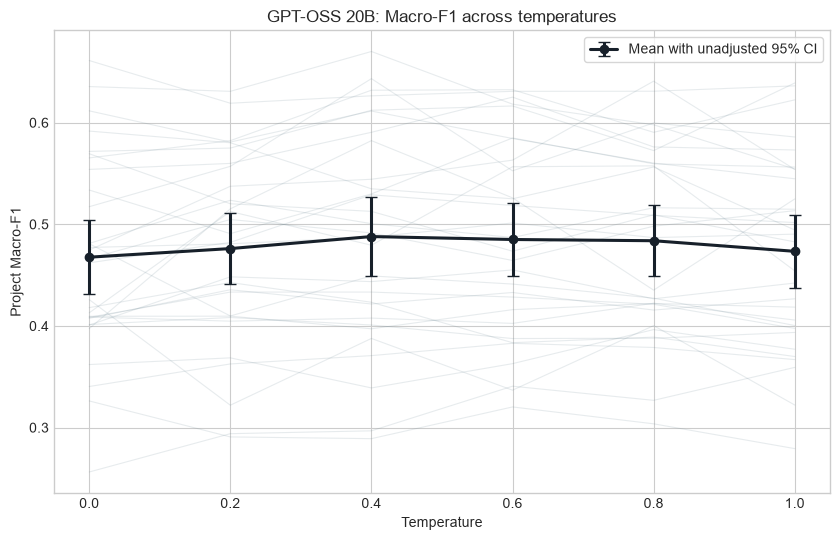

In [4]:
import matplotlib.pyplot as plt
from scipy.stats import t as student_t

ordered_metadata = metadata.sort_values("Temperature")
ordered_columns = ordered_metadata["Configuration"].tolist()
ordered_temperatures = ordered_metadata["Temperature"].to_numpy()
values = df_clean[ordered_columns]

means = values.mean(axis=0).to_numpy()
standard_errors = values.sem(axis=0).to_numpy()
critical_t = student_t.ppf(0.975, df=len(values) - 1)
confidence_half_width = critical_t * standard_errors

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8.5, 5.5))

for _, project_values in values.iterrows():
    ax.plot(
        ordered_temperatures,
        project_values.to_numpy(),
        color="#607D8B",
        alpha=0.15,
        linewidth=0.8,
    )

ax.errorbar(
    ordered_temperatures,
    means,
    yerr=confidence_half_width,
    color="#17202A",
    marker="o",
    linewidth=2.2,
    capsize=4,
    label="Mean with unadjusted 95% CI",
    zorder=5,
)

ax.set_title(f"{model_name}: Macro-F1 across temperatures")
ax.set_xlabel("Temperature")
ax.set_ylabel("Project Macro-F1")
ax.set_xticks(ordered_temperatures)
ax.legend(frameon=True)
fig.tight_layout()
# fig.savefig(
#     "rq2_temperature_profile.png",
#     dpi=200,
#     bbox_inches="tight",
# )
plt.show()


## Reproducibility notes

- Complete-case filtering is applied once across every temperature configuration.
- The model is fixed as GPT-OSS 20B, and numerical temperature values are parsed from the `temp_<value>` column names.
- Mauchly's test is used only on the parametric route.
- Post-hoc tests are conditional on the omnibus result and use Holm correction, not uncorrected or selectively reported comparisons.
- Individual confidence intervals are descriptive and unadjusted for multiple comparisons.
- A non-significant omnibus result does not prove that all temperatures are equivalent.
- Runtime and initially unresolved counts are reported from their own inference measurements, not reconstructed from the Macro-F1 table.